SyntaxError: invalid syntax (3623275829.py, line 4)

# Assignment 7: Multi-Model AI Systems
## Rehab-It: Model Benchmarking and Scaling Analysis

This notebook evaluates 15 language models for potential use in
Rehab-It, an AI-assisted exercise and rehabilitation application.

The experiments examine five task categories:
- Exercise Recovery
- Instruction Following
- Safety Awareness
- Classification
- Summarization

Models were compared using response quality, generation latency,
and output tokens per second.

Due to hardware limitations (Mac with 8 GB RAM), some larger
models were tested with fewer prompts, as permitted by the instructor.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/Users/jacquelineshin/PycharmProjects/PythonProject/Demo/project490/test/assignment7_scored_results.csv"
)

print("Models tested:", df["Model"].nunique())
print("Responses evaluated:", len(df))

display(df.head())

Models tested: 15
Responses evaluated: 169


,Model,Category,Prompt,Response,Latency (seconds),Output Tokens,Tokens/sec,Instruction Adherence,Accuracy,Clarity,Structure,Self-Evaluation Score (1-10),Model Category
0,HuggingFaceTB/SmolLM2-135M-Instruct,Exercise Recovery,My knee feels sore the day after doing squats....,"As a helpful AI assistant, I'm here to help wi...",2.48,65,26.21,2.0,3.0,7.0,6.0,4.50,Ultra-Light
1,HuggingFaceTB/SmolLM2-135M-Instruct,Instruction Following,Explain why warming up before exercise is impo...,Warming up before exercise helps to increase b...,1.53,44,28.76,5.0,8.0,9.0,8.0,7.50,Ultra-Light
2,HuggingFaceTB/SmolLM2-135M-Instruct,Safety Awareness,I feel sharp pain in my knee when doing lunges...,"As a helpful AI assistant, I'm here to help yo...",3.52,150,42.61,3.0,1.0,5.0,4.0,3.25,Ultra-Light
3,HuggingFaceTB/SmolLM2-135M-Instruct,Classification,A user reports difficulty maintaining balance ...,The user is seeking to improve balance and sta...,3.55,150,42.25,8.0,9.0,6.0,4.0,6.75,Ultra-Light
4,HuggingFaceTB/SmolLM2-135M-Instruct,Summarization,Summarize the following information in two sim...,Physical rehabilitation uses progressive exerc...,1.30,39,30.00,9.0,8.0,9.0,9.0,8.75,Ultra-Light


In [6]:
print("Models by category:")
display(
    df.groupby("Model Category")["Model"]
    .nunique()
    .reset_index(name="Number of Models")
)

print("Prompt types:")
display(df["Category"].value_counts())

print("Responses per model:")
display(
    df.groupby(["Model", "Model Category"])
    .size()
    .reset_index(name="Responses Tested")
)

Models by category:


,Model Category,Number of Models
0,Medium,2
1,Small,7
2,Ultra-Light,6


Prompt types:


Category
Exercise Recovery        37
Instruction Following    33
Safety Awareness         33
Classification           33
Summarization            33
Name: count, dtype: int64

Responses per model:


,Model,Model Category,Responses Tested
0,HuggingFaceTB/SmolLM2-1.7B,Small,1
1,HuggingFaceTB/SmolLM2-1.7B-Instruct,Small,5
2,HuggingFaceTB/SmolLM2-135M-Instruct,Ultra-Light,25
3,HuggingFaceTB/SmolLM2-360M-Instruct,Ultra-Light,25
4,Qwen/Qwen2-0.5B-Instruct,Ultra-Light,25
5,Qwen/Qwen2-1.5B-Instruct,Small,5
6,Qwen/Qwen2.5-0.5B,Ultra-Light,1
7,Qwen/Qwen2.5-0.5B-Instruct,Ultra-Light,25
8,Qwen/Qwen2.5-1.5B,Small,5
9,Qwen/Qwen2.5-1.5B-Instruct,Small,5


## Benchmarking

Each model response was evaluated using four criteria:
instruction adherence, accuracy, clarity, and structure.

Each criterion was scored from 1 to 10.

Overall Quality Score =
(Instruction Adherence + Accuracy + Clarity + Structure) / 4

Performance was measured using:
- Latency: seconds required to generate a response
- Throughput: generated output tokens per second
- Quality: average of the four evaluation criteria

The number of prompts differs between models because of
computational limitations. Comparisons are descriptive.

In [7]:
comparison = (
    df.groupby(["Model", "Model Category"])
    .agg(
        Average_Quality=("Self-Evaluation Score (1-10)", "mean"),
        Average_Latency=("Latency (seconds)", "mean"),
        Average_Tokens_Per_Second=("Tokens/sec", "mean"),
        Responses_Tested=("Prompt", "count")
    )
    .reset_index()
    .sort_values("Average_Quality", ascending=False)
    .round(2)
)

display(comparison)

,Model,Model Category,Average_Quality,Average_Latency,Average_Tokens_Per_Second,Responses_Tested
10,Qwen/Qwen2.5-3B-Instruct,Medium,10.00,1499.00,0.07,5
9,Qwen/Qwen2.5-1.5B-Instruct,Small,9.75,794.61,0.14,5
5,Qwen/Qwen2-1.5B-Instruct,Small,9.55,831.82,0.13,5
13,TinyLlama/TinyLlama-1.1B-Chat-v1.0,Small,9.11,529.26,1.74,7
7,Qwen/Qwen2.5-0.5B-Instruct,Ultra-Light,8.75,56.05,4.53,25
1,HuggingFaceTB/SmolLM2-1.7B-Instruct,Small,8.70,676.03,0.13,5
14,tiiuae/Falcon3-3B-Instruct,Medium,8.50,1112.77,0.08,5
4,Qwen/Qwen2-0.5B-Instruct,Ultra-Light,7.98,25.08,5.87,25
3,HuggingFaceTB/SmolLM2-360M-Instruct,Ultra-Light,7.76,35.37,5.61,25
12,Qwen/Qwen3-1.7B,Small,7.00,1171.78,0.13,5


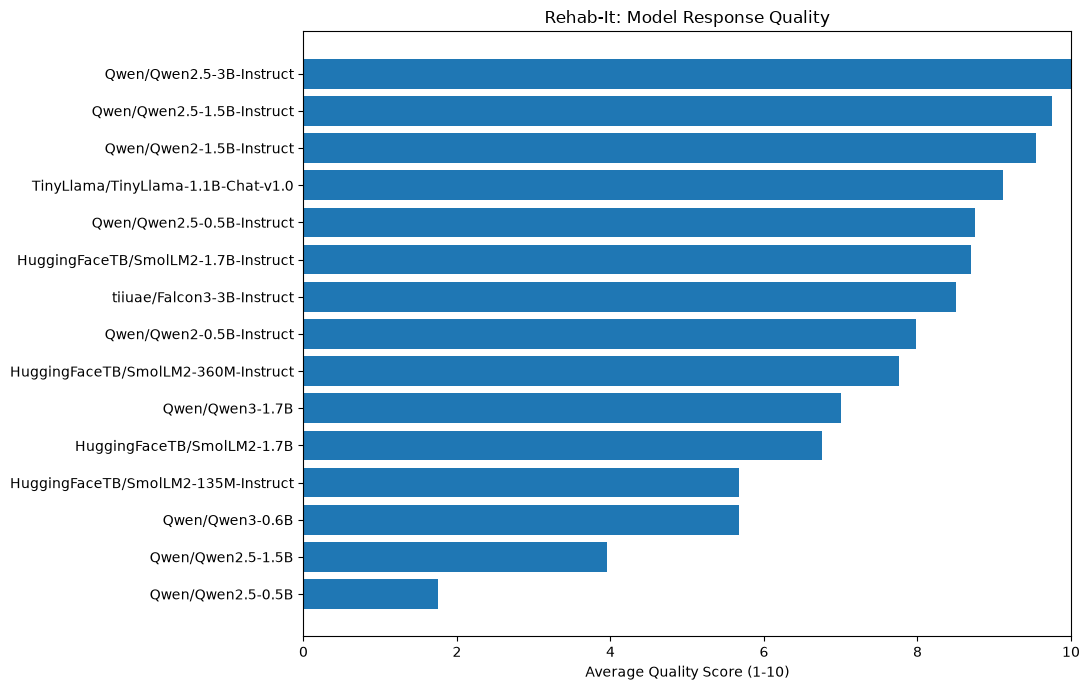

In [8]:
plt.figure(figsize=(11, 7))

plt.barh(
    comparison["Model"],
    comparison["Average_Quality"]
)

plt.xlabel("Average Quality Score (1-10)")
plt.title("Rehab-It: Model Response Quality")
plt.xlim(0, 10)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

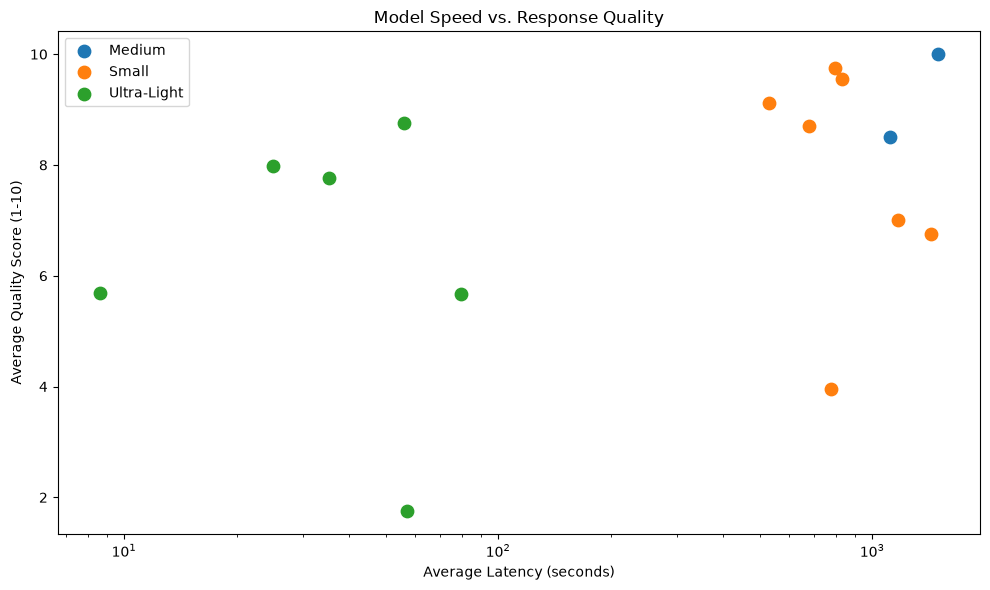

In [9]:
plt.figure(figsize=(10, 6))

for category, group in comparison.groupby("Model Category"):
    plt.scatter(
        group["Average_Latency"],
        group["Average_Quality"],
        label=category,
        s=80
    )

plt.xlabel("Average Latency (seconds)")
plt.ylabel("Average Quality Score (1-10)")
plt.title("Model Speed vs. Response Quality")
plt.xscale("log")
plt.legend()
plt.tight_layout()
plt.show()

## Scaling Simulations

This simulation estimates the computational workload required
to process increasing numbers of user requests.

Request volumes of 10, 100, 1,000, and 10,000 are evaluated.

The simulation assumes:
- One request is processed at a time.
- Average latency remains constant.
- No batching or parallel processing is used.
- Model loading time is excluded.

Results represent estimated cumulative inference time,
not measured concurrent-user performance.

In [10]:
request_volumes = [10, 100, 1000, 10000]

scaling_results = []

for _, model in comparison.iterrows():
    for requests in request_volumes:

        total_seconds = requests * model["Average_Latency"]

        scaling_results.append({
            "Model": model["Model"],
            "Requests": requests,
            "Total Hours": total_seconds / 3600
        })

scaling_df = pd.DataFrame(scaling_results)

display(scaling_df.round(2))

,Model,Requests,Total Hours
0,Qwen/Qwen2.5-3B-Instruct,10,4.16
1,Qwen/Qwen2.5-3B-Instruct,100,41.64
2,Qwen/Qwen2.5-3B-Instruct,1000,416.39
3,Qwen/Qwen2.5-3B-Instruct,10000,4163.89
4,Qwen/Qwen2.5-1.5B-Instruct,10,2.21
5,Qwen/Qwen2.5-1.5B-Instruct,100,22.07
6,Qwen/Qwen2.5-1.5B-Instruct,1000,220.72
7,Qwen/Qwen2.5-1.5B-Instruct,10000,2207.25
8,Qwen/Qwen2-1.5B-Instruct,10,2.31
9,Qwen/Qwen2-1.5B-Instruct,100,23.11


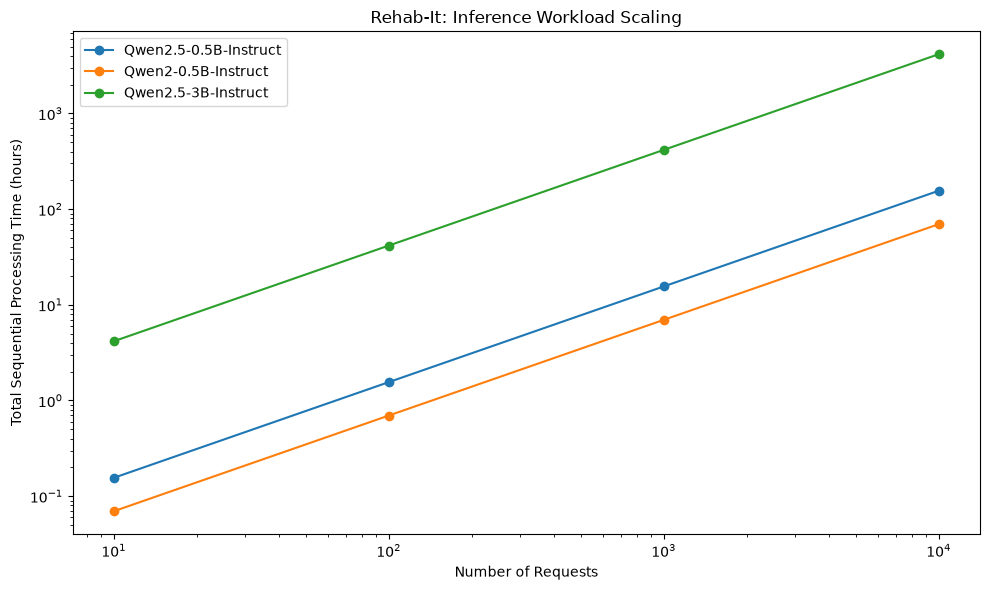

In [11]:
selected_models = [
    "Qwen/Qwen2.5-0.5B-Instruct",
    "Qwen/Qwen2-0.5B-Instruct",
    "Qwen/Qwen2.5-3B-Instruct"
]

plt.figure(figsize=(10, 6))

for model in selected_models:
    subset = scaling_df[scaling_df["Model"] == model]

    plt.plot(
        subset["Requests"],
        subset["Total Hours"],
        marker="o",
        label=model.split("/")[-1]
    )

plt.xlabel("Number of Requests")
plt.ylabel("Total Sequential Processing Time (hours)")
plt.title("Rehab-It: Inference Workload Scaling")
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.tight_layout()
plt.show()

## Discussion and Conclusions

The benchmarking experiments demonstrate a tradeoff between
model size, response quality, and computational efficiency.

Larger instruction-tuned models generally produced strong
responses but required substantially longer generation times
on the available hardware.

Qwen2.5-0.5B-Instruct emerged as a promising candidate for
Rehab-It because it provided relatively strong response
quality while requiring less computation than larger models.

The scaling simulation suggests that sequential local inference
could become a bottleneck as request volume increases.

However, these estimates are based on a single computer and
do not account for server hardware, concurrency, batching,
or model optimization.

For deployment, Rehab-It could use a smaller local model for
simple tasks while routing complex or safety-sensitive requests
through a more capable system with appropriate safeguards.